# Predicting Future PostgreSQL Lock Contention

## Reproducible Machine-Learning Experimental Record

**Project:** Lock Contention Prediction for PostgreSQL Reservation Workloads  
**Task:** Binary classification of whether high lock contention will occur in the next 30 seconds  
**Dataset:** Controlled PostgreSQL reservation experiments with Locust-generated demand  
**Final deployed model:** StandardScaler + LogisticRegression  
**Notebook scope:** Offline data science, model selection, frozen test evaluation, artifact verification, and deployment-compatible inference

This notebook consolidates the project's existing, versioned data and machine-learning workflow into one academically structured record. It executes the same feature contract, split strategy, model definitions, selection criterion, threshold, and serialized artifact used by the application. It does not replace the production modules; those modules remain the authoritative implementation.

> **Interpretation boundary:** Phase 7 proves that the active model can generate and persist predictions during a synchronized workload. Because the live demonstration predictions have not yet matured into `actual_label` values, live predictive accuracy is not claimed here. The performance claims in this notebook come from the frozen, experiment-grouped offline test set.

## 1. Research question and methodology

The research question is:

> Can measurements available at sampling time predict whether a high PostgreSQL lock-contention condition will occur within the following 30 seconds?

One observation corresponds to one complete metric sample at time $t$. Its binary target, `future_high_contention_30s`, is positive when at least one eligible sample in $(t, t+30	ext{ seconds}]$ satisfies any of the following:

- `blocked_sessions >= 2`
- `waiting_locks >= 2`
- cumulative `deadlock_delta >= 1`
- `timeout_rate > 0`

The current sample provides 18 numeric model features. Future-window evidence is retained in the source dataset for label auditing but is prohibited from model input. The methodology is:

1. validate a frozen dataset and feature contract;
2. split whole experiments into train, validation, and test groups;
3. fit a dummy baseline, logistic regression, and random forest on train only;
4. select the model by validation PR-AUC;
5. select its decision threshold by validation $F_2$, prioritizing recall;
6. evaluate the frozen model once on the untouched test split;
7. verify and exercise the same artifact and inference path used by the application.

## 2. Environment, configuration, and reproducibility

From the repository root, install the locked application dependencies and notebook-only visualization/kernel dependencies with:

```bash
python -m pip install -r notebooks/requirements-notebook.txt
```

The notebook does not require a running API, PostgreSQL connection, credential, or environment-specific absolute path.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import random
import sys
import tempfile
import time
import warnings

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

RANDOM_SEED = 3301
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "model_training").is_dir():
    if (PROJECT_ROOT.parent / "model_training").is_dir():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError(
            "Run this notebook from the repository root or notebooks directory."
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATASET_PATH = PROJECT_ROOT / "data/processed/contention_training_dataset_v1.csv"
SPLIT_DIR = PROJECT_ROOT / "data/processed/splits/contention_training_dataset_v1"
BASELINE_REPORT_PATH = PROJECT_ROOT / "docs/model_training/baseline_results_v1.json"
SELECTION_REPORT_PATH = PROJECT_ROOT / "docs/model_training/candidate_selection_v1.json"
FINAL_REPORT_PATH = PROJECT_ROOT / "docs/model_training/final_test_evaluation_v1.json"
PHASE7_REPORT_PATH = PROJECT_ROOT / "docs/model_training/phase7_completion_v1.json"
ARTIFACT_PATH = PROJECT_ROOT / "artifacts/models/contention_candidate_v1.joblib"

pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.figsize": (9, 5.5),
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

environment = pd.DataFrame(
    {
        "Component": ["Python", "NumPy", "pandas", "scikit-learn", "Matplotlib", "seaborn"],
        "Version": [
            platform.python_version(), np.__version__, pd.__version__,
            sklearn.__version__, mpl.__version__, sns.__version__,
        ],
    }
)
print("Project root resolved successfully.")
print(f"Random seed: {RANDOM_SEED}")
display(environment)

,Component,Version
0,Python,3.12.13
1,NumPy,2.3.5
2,pandas,2.2.3
3,scikit-learn,1.8.0
4,Matplotlib,3.10.8
5,seaborn,0.13.2


Project root resolved successfully.
Random seed: 3301


The repository locks scikit-learn `1.9.0` in `requirements-lock.txt`; authoritative reproduction should use that environment. This notebook records the runtime version above and later checks the serialized model checksum and every final metric. A different scikit-learn version may emit a model-persistence warning even when predictions reproduce exactly.

## 3. Load the frozen dataset, splits, and evidence reports

In [2]:
required_paths = [
    DATASET_PATH,
    *(SPLIT_DIR / f"{name}.csv" for name in ("train", "validation", "test")),
    BASELINE_REPORT_PATH,
    SELECTION_REPORT_PATH,
    FINAL_REPORT_PATH,
    PHASE7_REPORT_PATH,
    ARTIFACT_PATH,
]
missing_paths = [str(path) for path in required_paths if not path.is_file()]
assert not missing_paths, f"Missing required project files: {missing_paths}"

full_data = pd.read_csv(DATASET_PATH, parse_dates=["sampled_at"])
splits = {
    name: pd.read_csv(SPLIT_DIR / f"{name}.csv", parse_dates=["sampled_at"])
    for name in ("train", "validation", "test")
}
with BASELINE_REPORT_PATH.open(encoding="utf-8") as file:
    baseline_report = json.load(file)
with SELECTION_REPORT_PATH.open(encoding="utf-8") as file:
    selection_report = json.load(file)
with FINAL_REPORT_PATH.open(encoding="utf-8") as file:
    final_report = json.load(file)
with PHASE7_REPORT_PATH.open(encoding="utf-8") as file:
    phase7_report = json.load(file)

TARGET = baseline_report["dataset"]["target_column"]
FEATURES = tuple(baseline_report["dataset"]["feature_columns"])
FUTURE_EVIDENCE = (
    "future_max_blocked_sessions_30s",
    "future_max_waiting_locks_30s",
    "future_deadlock_delta_sum_30s",
    "future_max_timeout_rate_30s",
    "future_max_p95_latency_ms_30s",
)

dataset_overview = pd.DataFrame(
    {
        "Measure": [
            "Rows", "Columns", "Experiments", "Features",
            "Negative labels", "Positive labels", "Prediction horizon",
        ],
        "Value": [
            len(full_data), full_data.shape[1], full_data["experiment_run_id"].nunique(),
            len(FEATURES), int((full_data[TARGET] == 0).sum()),
            int((full_data[TARGET] == 1).sum()), "30 seconds",
        ],
    }
)
display(dataset_overview)
display(full_data.head(3))

,Measure,Value
0,Rows,2666
1,Columns,36
2,Experiments,60
3,Features,18
4,Negative labels,1106
5,Positive labels,1560
6,Prediction horizon,30 seconds


,schema_version,experiment_run_id,experiment_name,sampled_at,collector_version,code_version,booking_mode,random_seed,sample_interval_sec,simulated_work_ms,is_complete,quality_notes,active_transactions,blocked_sessions,waiting_locks,total_locks,total_connections,connection_utilization,estimated_wait_age_ms,deadlock_delta,configured_users,active_users,requests_per_sec,mean_latency_ms,p95_latency_ms,failure_rate,hotspot_ratio,booking_success_rate,conflict_rate,timeout_rate,future_max_blocked_sessions_30s,future_max_waiting_locks_30s,future_deadlock_delta_sum_30s,future_max_timeout_rate_30s,future_max_p95_latency_ms_30s,future_high_contention_30s
0,1.0.0,0595fd05-a51b-457c-b8f6-cecd2d294b24,M31-v1.0.0-LOW-BURST-STANDARD-s4102,2026-08-25 13:51:38.929700+05:30,checkpoint-26-v1,6f6fddd1f9cf9979303c321bab8095e95da67eee,EXPERIMENT_RECYCLE,4102,2,75,True,[],1,0,0,7,4,0.04,0.0,0,8,2,9.894,92.237,107.311,0.0,0.2500,1.0,0.0,0.0,0,0,0,0.0,121.656,0
1,1.0.0,0595fd05-a51b-457c-b8f6-cecd2d294b24,M31-v1.0.0-LOW-BURST-STANDARD-s4102,2026-08-25 13:51:40.924389+05:30,checkpoint-26-v1,6f6fddd1f9cf9979303c321bab8095e95da67eee,EXPERIMENT_RECYCLE,4102,2,75,True,[],1,0,0,23,4,0.04,0.0,0,8,2,13.536,90.643,96.918,0.0,0.2963,1.0,0.0,0.0,0,0,0,0.0,121.656,0
2,1.0.0,0595fd05-a51b-457c-b8f6-cecd2d294b24,M31-v1.0.0-LOW-BURST-STANDARD-s4102,2026-08-25 13:51:42.925373+05:30,checkpoint-26-v1,6f6fddd1f9cf9979303c321bab8095e95da67eee,EXPERIMENT_RECYCLE,4102,2,75,True,[],1,0,0,23,4,0.04,0.0,0,8,2,13.493,88.737,91.590,0.0,0.1481,1.0,0.0,0.0,1,1,0,0.0,121.656,0


The dataset contains provenance, experiment metadata, present-time features, future-window label evidence, and the target. MovieLens 1M is part of the wider repository only as an external source for demand-profile calibration; it does **not** supply booking, PostgreSQL lock, or target-label records.

In [3]:
column_catalog = pd.DataFrame(
    {
        "Column": full_data.columns,
        "dtype": full_data.dtypes.astype(str).values,
        "Non-null": full_data.notna().sum().values,
        "Unique": full_data.nunique(dropna=False).values,
        "Role": [
            "target" if column == TARGET else
            "model feature" if column in FEATURES else
            "future label evidence (forbidden input)" if column in FUTURE_EVIDENCE else
            "metadata / provenance"
            for column in full_data.columns
        ],
    }
)
display(column_catalog)

,Column,dtype,Non-null,Unique,Role
0,schema_version,object,2666,1,metadata / provenance
1,experiment_run_id,object,2666,60,metadata / provenance
2,experiment_name,object,2666,60,metadata / provenance
3,sampled_at,"datetime64[ns, UTC+05:30]",2666,2666,metadata / provenance
4,collector_version,object,2666,1,metadata / provenance
5,code_version,object,2666,1,metadata / provenance
6,booking_mode,object,2666,1,metadata / provenance
7,random_seed,int64,2666,2,metadata / provenance
8,sample_interval_sec,int64,2666,1,metadata / provenance
9,simulated_work_ms,int64,2666,2,metadata / provenance


## 4. Data quality and preprocessing audit

In [4]:
RATE_FEATURES = (
    "connection_utilization", "failure_rate", "hotspot_ratio",
    "booking_success_rate", "conflict_rate", "timeout_rate",
)
numeric_features = full_data.loc[:, FEATURES].apply(pd.to_numeric, errors="coerce")

quality_summary = pd.DataFrame(
    {
        "Check": [
            "Missing cells (entire dataset)",
            "Duplicate full rows",
            "Duplicate experiment/timestamp keys",
            "Non-finite feature values",
            "Negative feature values",
            "Rate values outside [0, 1]",
            "Non-binary targets",
            "Incomplete samples",
        ],
        "Violations": [
            int(full_data.isna().sum().sum()),
            int(full_data.duplicated().sum()),
            int(full_data.duplicated(["experiment_run_id", "sampled_at"]).sum()),
            int((~np.isfinite(numeric_features.to_numpy(dtype=float))).sum()),
            int((numeric_features < 0).sum().sum()),
            int(sum(((full_data[c] < 0) | (full_data[c] > 1)).sum() for c in RATE_FEATURES)),
            int((~full_data[TARGET].isin([0, 1])).sum()),
            int((~full_data["is_complete"].astype(bool)).sum()),
        ],
    }
)
display(quality_summary)
assert (quality_summary["Violations"] == 0).all()
print("All mandatory data-quality checks passed.")

,Check,Violations
0,Missing cells (entire dataset),0
1,Duplicate full rows,0
2,Duplicate experiment/timestamp keys,0
3,Non-finite feature values,0
4,Negative feature values,0
5,"Rate values outside [0, 1]",0
6,Non-binary targets,0
7,Incomplete samples,0


All mandatory data-quality checks passed.


No imputation or categorical encoding is needed because the approved model inputs are complete numeric telemetry. Counts, measurements, and rates are already constrained to valid ranges. The selected logistic model performs standardization **inside** an sklearn `Pipeline`, so the scaler is fitted only on training data and reused for validation, test, and inference. The random forest and dummy baseline require no scaling.

Outliers are not automatically removed: extreme latency, lock, and load measurements can be genuine contention signals. They are summarized below and retained unless a data-quality rule identifies them as invalid.

In [5]:
descriptive_statistics = numeric_features.describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]
).T
descriptive_statistics["IQR"] = (
    descriptive_statistics["75%"] - descriptive_statistics["25%"]
)
display(descriptive_statistics)

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,IQR
active_transactions,2666.0,6.0049,3.1450,0.000,0.0000,3.0000,6.0000,9.7500,10.0000,10.0000,11.000,6.7500
blocked_sessions,2666.0,1.4542,2.0776,0.000,0.0000,0.0000,0.0000,2.0000,6.0000,7.0000,8.000,2.0000
waiting_locks,2666.0,1.4550,2.0761,0.000,0.0000,0.0000,0.0000,2.0000,6.0000,7.0000,8.000,2.0000
total_locks,2666.0,135.7948,73.8190,0.000,0.0000,70.0000,132.0000,210.0000,233.0000,238.0000,306.000,140.0000
total_connections,2666.0,8.6433,2.8722,3.000,4.0000,6.0000,9.0000,12.0000,12.0000,12.0000,13.000,6.0000
connection_utilization,2666.0,0.0864,0.0287,0.030,0.0400,0.0600,0.0900,0.1200,0.1200,0.1200,0.130,0.0600
estimated_wait_age_ms,2666.0,177.5623,333.2205,0.000,0.0000,0.0000,0.0000,185.2032,983.5180,1506.1026,2049.040,185.2032
deadlock_delta,2666.0,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0000
configured_users,2666.0,13.0075,5.0009,8.000,8.0000,8.0000,18.0000,18.0000,18.0000,18.0000,18.000,10.0000
active_users,2666.0,8.0964,4.9377,1.000,1.0000,5.0000,8.0000,9.0000,18.0000,18.0000,18.000,4.0000


## 5. Exploratory data analysis

,Split,Rows,Experiments,Negative,Positive,Positive rate
0,Train,1864,42,772,1092,0.5858
1,Validation,400,9,166,234,0.5850
2,Test,402,9,168,234,0.5821


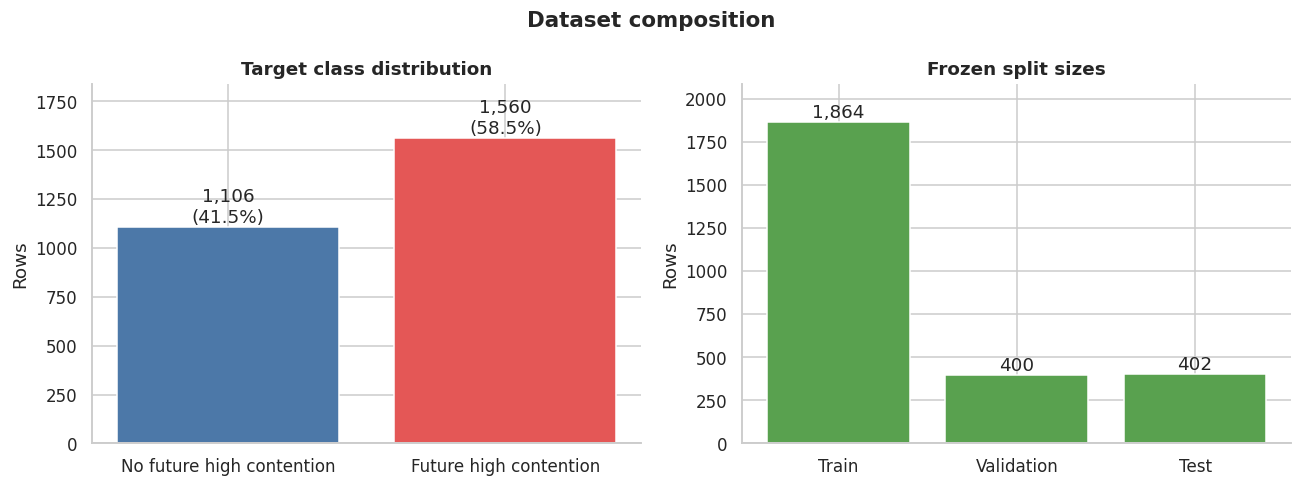

In [6]:
split_summary = []
for name, frame in splits.items():
    split_summary.append(
        {
            "Split": name.title(),
            "Rows": len(frame),
            "Experiments": frame["experiment_run_id"].nunique(),
            "Negative": int((frame[TARGET] == 0).sum()),
            "Positive": int((frame[TARGET] == 1).sum()),
            "Positive rate": float(frame[TARGET].mean()),
        }
    )
split_summary = pd.DataFrame(split_summary)
display(split_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
target_counts = full_data[TARGET].value_counts().sort_index()
axes[0].bar(["No future high contention", "Future high contention"], target_counts.values,
            color=["#4C78A8", "#E45756"])
axes[0].set_title("Target class distribution")
axes[0].set_ylabel("Rows")
axes[0].set_ylim(0, target_counts.max() * 1.18)
for i, value in enumerate(target_counts.values):
    axes[0].text(i, value + 25, f"{value:,}\n({value / len(full_data):.1%})", ha="center")

axes[1].bar(split_summary["Split"], split_summary["Rows"], color="#59A14F")
axes[1].set_title("Frozen split sizes")
axes[1].set_ylabel("Rows")
axes[1].set_ylim(0, split_summary["Rows"].max() * 1.12)
for i, value in enumerate(split_summary["Rows"]):
    axes[1].text(i, value + 25, f"{value:,}", ha="center")
fig.suptitle("Dataset composition", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

The positive class represents 58.5% of observations, so this is not an extreme class-imbalance problem. Nevertheless, accuracy alone is insufficient: false negatives are costly because they correspond to missed future contention. PR-AUC supports probability-ranking comparison, while $F_2$ gives recall twice the weight of precision during threshold selection.

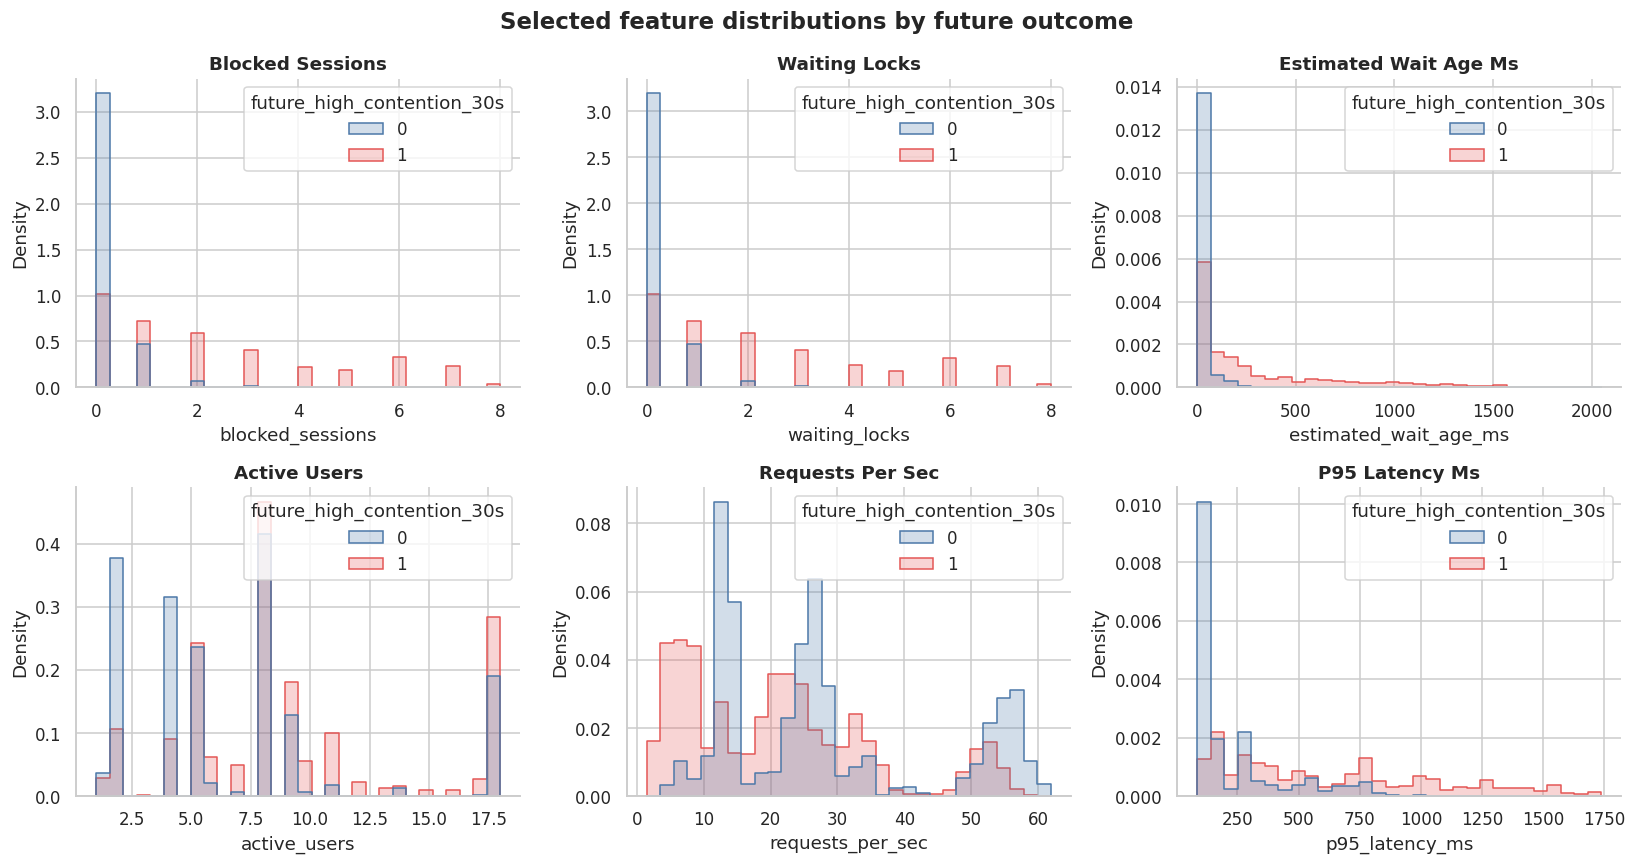

In [7]:
selected_for_distribution = [
    "blocked_sessions", "waiting_locks", "estimated_wait_age_ms",
    "active_users", "requests_per_sec", "p95_latency_ms",
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for axis, feature in zip(axes.ravel(), selected_for_distribution):
    sns.histplot(
        data=full_data, x=feature, hue=TARGET, bins=30,
        stat="density", common_norm=False, element="step", ax=axis,
        palette={0: "#4C78A8", 1: "#E45756"},
    )
    axis.set_title(feature.replace("_", " ").title())
    axis.set_ylabel("Density")
fig.suptitle("Selected feature distributions by future outcome", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

,Spearman correlation with target
blocked_sessions,0.6001
waiting_locks,0.5987
estimated_wait_age_ms,0.5955
p95_latency_ms,0.5644
hotspot_ratio,0.5578
mean_latency_ms,0.5265
total_locks,0.4171
active_transactions,0.3919
total_connections,0.3859
connection_utilization,0.3859


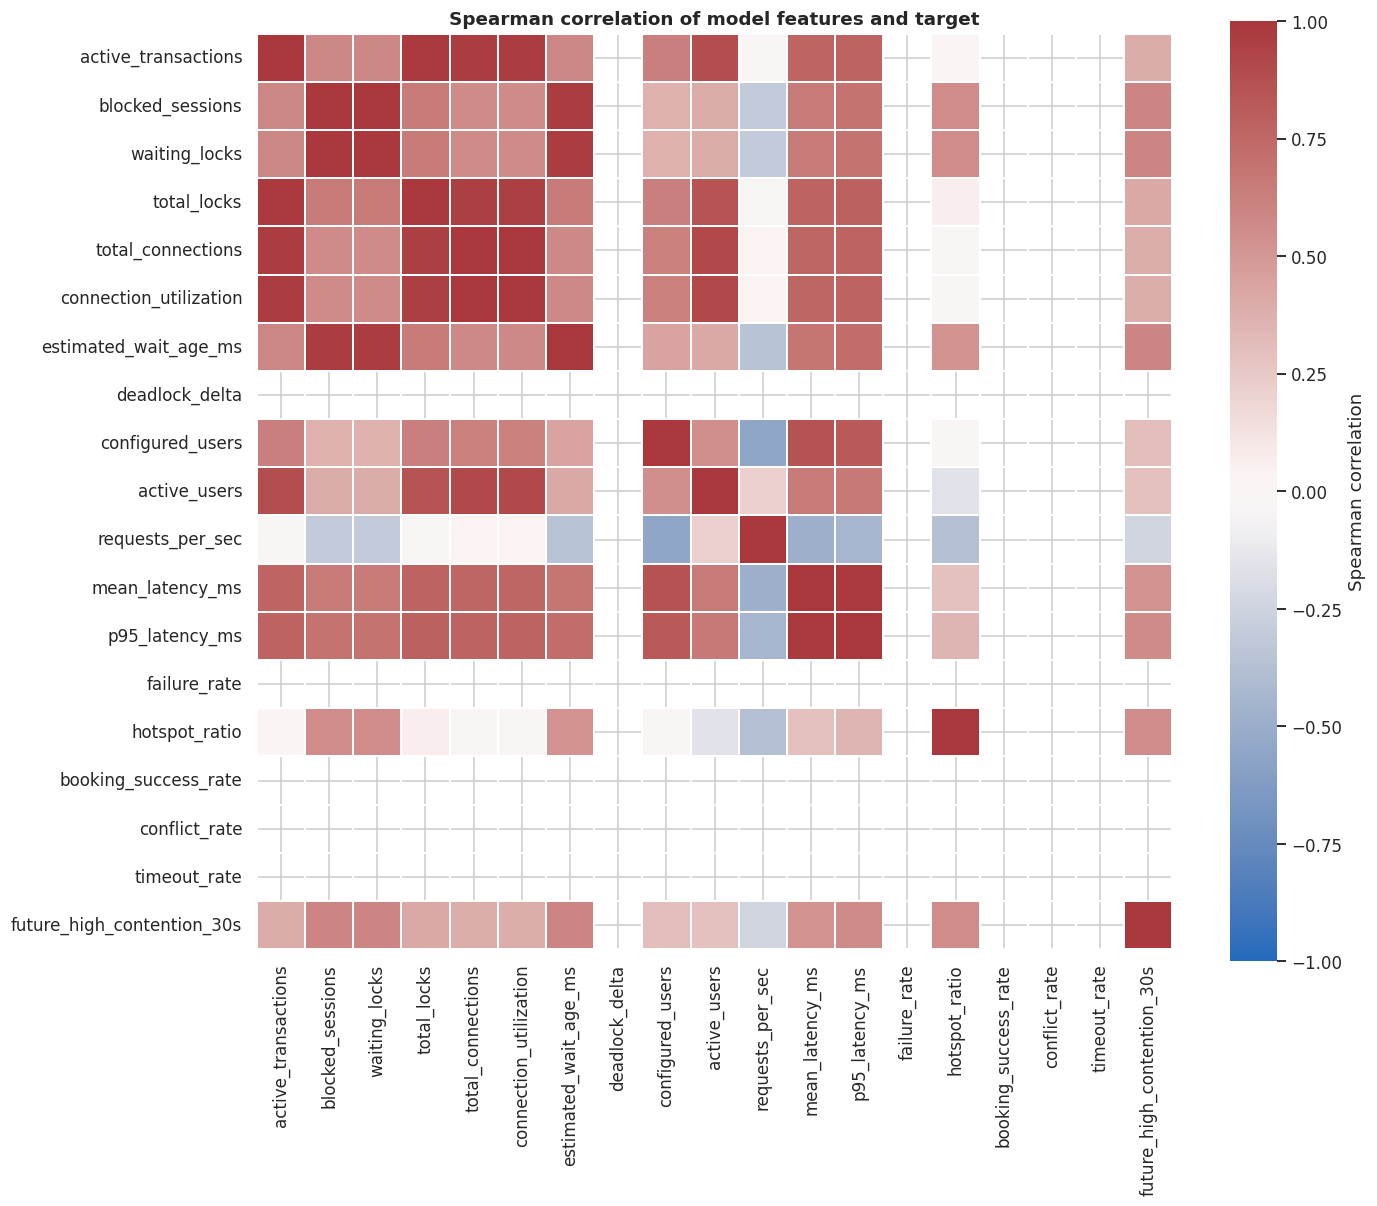

In [8]:
correlation = full_data.loc[:, [*FEATURES, TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(
    correlation, cmap="vlag", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.2, cbar_kws={"label": "Spearman correlation"}, ax=ax,
)
ax.set_title("Spearman correlation of model features and target")
plt.tight_layout()
plt.show()

target_correlations = (
    correlation[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
    .rename("Spearman correlation with target").to_frame()
)
display(target_correlations)

Correlation is descriptive rather than causal. Several measurements are expected to be correlated because they observe the same underlying workload and lock state. Logistic regression can still provide a compact deployable model, but coefficient magnitudes should be interpreted as conditional associations after standardization—not as causal effects.

## 6. Feature contract and leakage prevention

In [9]:
feature_contract = pd.DataFrame(
    {
        "Approved model feature": FEATURES,
        "Available at prediction time": True,
    }
)
display(feature_contract)

leakage_checks = {
    "Target excluded from features": TARGET not in FEATURES,
    "Future evidence excluded from features": set(FUTURE_EVIDENCE).isdisjoint(FEATURES),
    "Experiment identifier excluded": "experiment_run_id" not in FEATURES,
    "Timestamp excluded": "sampled_at" not in FEATURES,
    "Experimental controls excluded": {"random_seed", "simulated_work_ms", "code_version"}.isdisjoint(FEATURES),
}
display(pd.Series(leakage_checks, name="Passed").to_frame())
assert all(leakage_checks.values())

,Approved model feature,Available at prediction time
0,active_transactions,True
1,blocked_sessions,True
2,waiting_locks,True
3,total_locks,True
4,total_connections,True
5,connection_utilization,True
6,estimated_wait_age_ms,True
7,deadlock_delta,True
8,configured_users,True
9,active_users,True


,Passed
Target excluded from features,True
Future evidence excluded from features,True
Experiment identifier excluded,True
Timestamp excluded,True
Experimental controls excluded,True


The deployed model deliberately performs no additional derived feature engineering. This keeps the feature schema stable and ensures every input is directly observable from a complete metric sample. Future-label evidence, identifiers, timestamps, experiment completion fields, and experimental controls remain metadata. This conservative contract reduces leakage risk and aligns notebook inference with application inference.

## 7. Train/validation/test strategy

In [10]:
experiment_sets = {
    name: set(frame["experiment_run_id"].astype(str))
    for name, frame in splits.items()
}
overlap = pd.DataFrame(
    [
        {"Pair": "train ∩ validation", "Overlapping experiments": len(experiment_sets["train"] & experiment_sets["validation"])},
        {"Pair": "train ∩ test", "Overlapping experiments": len(experiment_sets["train"] & experiment_sets["test"])},
        {"Pair": "validation ∩ test", "Overlapping experiments": len(experiment_sets["validation"] & experiment_sets["test"])},
    ]
)
display(overlap)
assert overlap["Overlapping experiments"].sum() == 0
assert set().union(*experiment_sets.values()) == set(full_data["experiment_run_id"].astype(str))
print("All 60 experiments occur in exactly one split.")

,Pair,Overlapping experiments
0,train ∩ validation,0
1,train ∩ test,0
2,validation ∩ test,0


All 60 experiments occur in exactly one split.


Whole experiments—not individual rows—are assigned to splits. This is essential because adjacent samples within one experiment are temporally related and share workload configuration. A row-level random split would leak near-duplicate experimental context across sets and exaggerate generalization.

The deterministic split seed is `3201`. Training uses 42 experiments, validation uses 9 for model and threshold selection, and 9 are reserved for one-time final evaluation. The project does not perform cross-validation: its authoritative comparison is the frozen grouped holdout. Adding cross-validation now would constitute a new experiment rather than documentation of the deployed selection procedure.

## 8. Baseline model training and validation comparison

In [11]:
from model_training.train_baselines import build_baseline_models, evaluate_probabilities

X_train = splits["train"].loc[:, FEATURES].to_numpy(dtype=float)
y_train = splits["train"][TARGET].to_numpy(dtype=np.int8)
X_validation = splits["validation"].loc[:, FEATURES].to_numpy(dtype=float)
y_validation = splits["validation"][TARGET].to_numpy(dtype=np.int8)
X_test = splits["test"].loc[:, FEATURES].to_numpy(dtype=float)
y_test = splits["test"][TARGET].to_numpy(dtype=np.int8)

models = build_baseline_models(random_seed=RANDOM_SEED)
fitted_models = {}
validation_probabilities = {}
executed_validation_results = []

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_seconds = time.perf_counter() - start
    probabilities = model.predict_proba(X_validation)[:, 1]
    metrics = evaluate_probabilities(
        true_labels=y_validation,
        probabilities=probabilities,
        threshold=0.5,
    )
    fitted_models[name] = model
    validation_probabilities[name] = probabilities
    executed_validation_results.append(
        {
            "Model": name,
            "PR-AUC": metrics["pr_auc"],
            "ROC-AUC": metrics["roc_auc"],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "F1": metrics["f1"],
            "Balanced accuracy": metrics["balanced_accuracy"],
            "Brier score": metrics["brier_score"],
            "Fit time (s)": training_seconds,
        }
    )

validation_comparison = pd.DataFrame(executed_validation_results).set_index("Model")
display(validation_comparison.round(4))

,PR-AUC,ROC-AUC,Precision,Recall,F1,Balanced accuracy,Brier score,Fit time (s)
Model,,,,,,,,
dummy_prior,0.5850,0.5000,0.5850,1.0000,0.7382,0.5000,0.2428,0.0004
logistic_regression,0.9712,0.9577,0.8162,0.9487,0.8775,0.8238,0.0935,0.0069
random_forest,0.9303,0.8883,0.7482,0.8889,0.8125,0.7336,0.1447,0.9029


In [12]:
stored_validation = pd.DataFrame(
    {
        model_name: {
            metric: model_data["metrics"][metric]
            for metric in ("pr_auc", "roc_auc", "precision", "recall", "f1", "balanced_accuracy", "brier_score")
        }
        for model_name, model_data in baseline_report["models"].items()
    }
).T
comparison_delta = validation_comparison.rename(
    columns={
        "PR-AUC": "pr_auc", "ROC-AUC": "roc_auc", "Precision": "precision",
        "Recall": "recall", "F1": "f1", "Balanced accuracy": "balanced_accuracy",
        "Brier score": "brier_score",
    }
)[stored_validation.columns] - stored_validation
display(comparison_delta)
print(f"Maximum absolute delta from frozen validation report: {comparison_delta.abs().to_numpy().max():.3e}")

,pr_auc,roc_auc,precision,recall,f1,balanced_accuracy,brier_score
Model,,,,,,,
dummy_prior,0.0000e+00,0.0000,0.0,0.0,0.0,0.0,0.0000e+00
logistic_regression,0.0000e+00,0.0000,0.0,0.0,0.0,0.0,-1.1102e-16
random_forest,1.4639e-05,-0.0006,0.0,0.0,0.0,0.0,4.1364e-04


Maximum absolute delta from frozen validation report: 6.436e-04


The prior-probability classifier is the minimum reference. Logistic regression substantially improves PR-AUC, ROC-AUC, and calibration error, and it outperforms the random forest on the selected validation criterion. Fit time is reported only as local contextual evidence; it is not used for model selection.

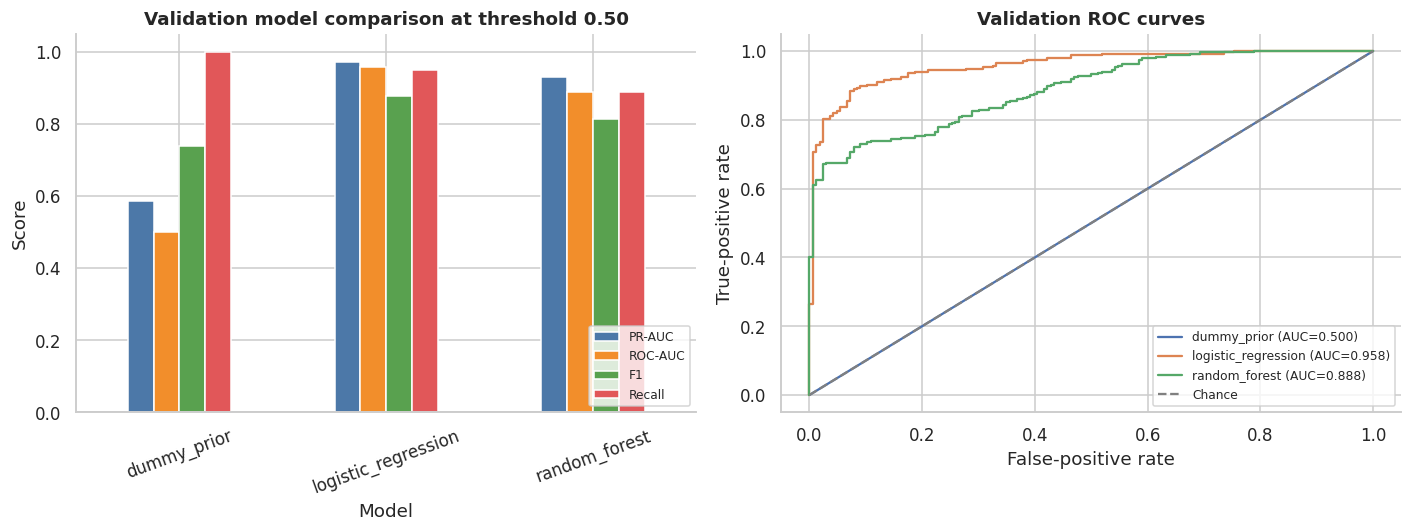

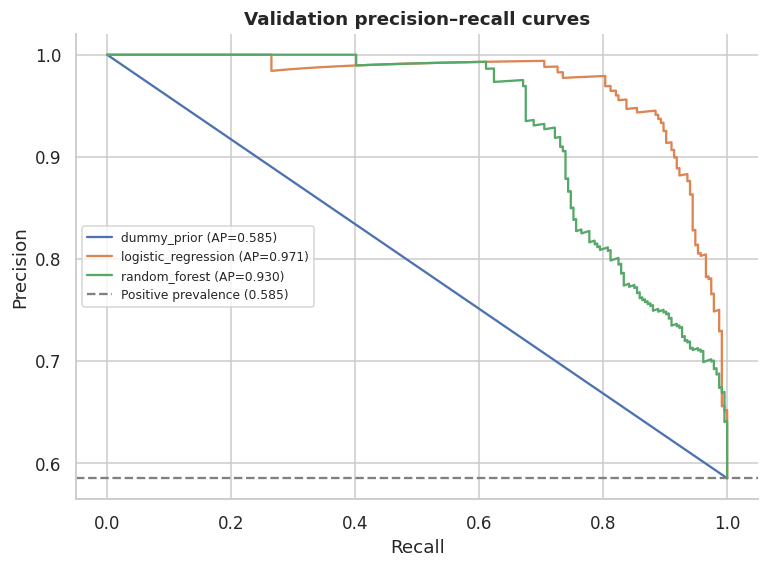

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
validation_comparison[["PR-AUC", "ROC-AUC", "F1", "Recall"]].plot(
    kind="bar", ylim=(0, 1.05), ax=axes[0], color=["#4C78A8", "#F28E2B", "#59A14F", "#E15759"]
)
axes[0].set_title("Validation model comparison at threshold 0.50")
axes[0].set_ylabel("Score")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(loc="lower right", fontsize=8)

for name, probabilities in validation_probabilities.items():
    fpr, tpr, _ = roc_curve(y_validation, probabilities)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_validation, probabilities):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
axes[1].set_title("Validation ROC curves")
axes[1].set_xlabel("False-positive rate")
axes[1].set_ylabel("True-positive rate")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5.5))
for name, probabilities in validation_probabilities.items():
    precision_curve, recall_curve, _ = precision_recall_curve(y_validation, probabilities)
    ax.plot(recall_curve, precision_curve, label=f"{name} (AP={average_precision_score(y_validation, probabilities):.3f})")
ax.axhline(y_validation.mean(), linestyle="--", color="gray", label=f"Positive prevalence ({y_validation.mean():.3f})")
ax.set_title("Validation precision–recall curves")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(fontsize=8)
plt.show()

## 9. Model selection and decision-threshold optimization

,threshold,f2,precision,recall,balanced_accuracy
29,0.34,0.9277,0.7476,0.9872,0.7586


Selected model: logistic_regression
Selection metric: validation PR-AUC = 0.971209


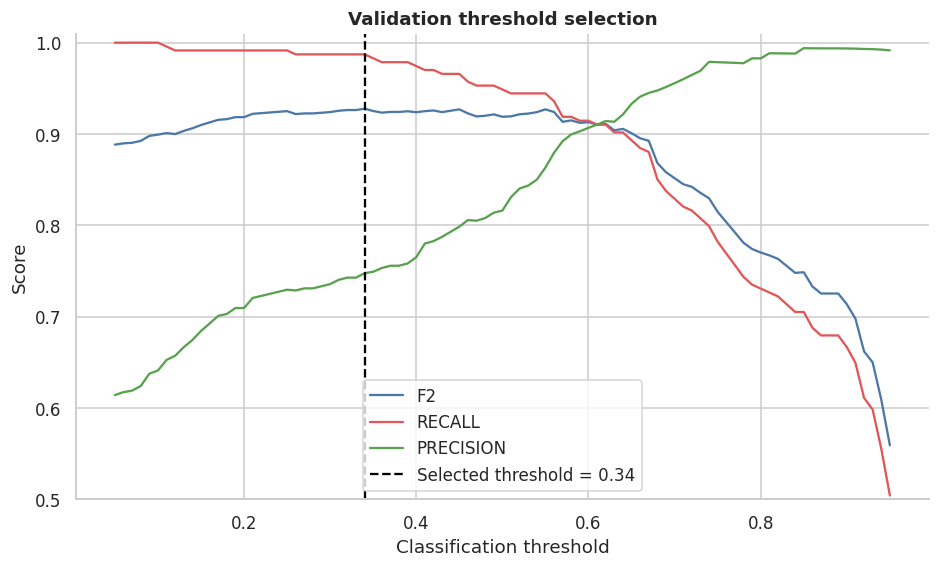

In [14]:
selected_model_name = max(
    baseline_report["models"],
    key=lambda name: baseline_report["models"][name]["metrics"]["pr_auc"],
)
assert selected_model_name == selection_report["selection"]["model_name"] == "logistic_regression"

threshold_search = pd.DataFrame(selection_report["validation"]["threshold_search"])
selected_threshold = float(selection_report["selection"]["selected_threshold"])
selected_threshold_row = threshold_search.loc[
    np.isclose(threshold_search["threshold"], selected_threshold),
    ["threshold", "f2", "precision", "recall", "balanced_accuracy"],
]
print(f"Selected model: {selected_model_name}")
print(f"Selection metric: validation PR-AUC = {baseline_report['models'][selected_model_name]['metrics']['pr_auc']:.6f}")
display(selected_threshold_row)

fig, ax = plt.subplots(figsize=(10, 5.5))
for metric, color in (("f2", "#4C78A8"), ("recall", "#E15759"), ("precision", "#59A14F")):
    ax.plot(threshold_search["threshold"], threshold_search[metric], label=metric.upper(), color=color)
ax.axvline(selected_threshold, linestyle="--", color="black", label=f"Selected threshold = {selected_threshold:.2f}")
ax.set_title("Validation threshold selection")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score")
ax.set_ylim(0.5, 1.01)
ax.legend()
plt.show()

Logistic regression was selected because it had the highest validation PR-AUC (`0.9712`). Its threshold was then chosen from 91 candidates between 0.05 and 0.95 by maximum validation $F_2$. The selected threshold of `0.34` achieved validation recall `0.9872`, precision `0.7476`, and $F_2$ `0.9277`.

This is the project's only tuning stage. No undocumented hyperparameter grid search is introduced here. The fixed candidate configurations favor reproducibility, and the lower threshold reflects the project's preference for detecting impending contention even at the cost of additional false alarms.

## 10. Frozen artifact and final test evaluation

In [15]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

artifact_hash = sha256(ARTIFACT_PATH)
expected_hash = final_report["model"]["model_sha256"]
assert artifact_hash == expected_hash

with warnings.catch_warnings(record=True) as artifact_warnings:
    warnings.simplefilter("always")
    artifact = joblib.load(ARTIFACT_PATH)

artifact_summary = pd.DataFrame(
    {
        "Property": [
            "Model name", "Schema version", "Feature count", "Threshold",
            "SHA-256", "Training scikit-learn", "Runtime scikit-learn",
            "Load warnings captured",
        ],
        "Value": [
            artifact["model_name"], artifact["schema_version"], len(artifact["feature_columns"]),
            artifact["classification_threshold"], artifact_hash,
            baseline_report["scikit_learn_version"], sklearn.__version__, len(artifact_warnings),
        ],
    }
)
display(artifact_summary)

,Property,Value
0,Model name,logistic_regression
1,Schema version,1.0.0
2,Feature count,18
3,Threshold,0.34
4,SHA-256,e255db6ee5d3a59c075b6249fc7d355e5107dd56b2ed7d...
5,Training scikit-learn,1.9.0
6,Runtime scikit-learn,1.8.0
7,Load warnings captured,3


In [16]:
test_probabilities = artifact["model"].predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype(np.int8)
test_matrix = confusion_matrix(y_test, test_predictions, labels=[0, 1])
computed_test_metrics = {
    "accuracy": accuracy_score(y_test, test_predictions),
    "balanced_accuracy": balanced_accuracy_score(y_test, test_predictions),
    "brier_score": brier_score_loss(y_test, test_probabilities),
    "precision": precision_score(y_test, test_predictions),
    "recall": recall_score(y_test, test_predictions),
    "f1": f1_score(y_test, test_predictions),
    "f2": fbeta_score(y_test, test_predictions, beta=2),
    "pr_auc": average_precision_score(y_test, test_probabilities),
    "roc_auc": roc_auc_score(y_test, test_probabilities),
}
stored_test_metrics = {
    key: final_report["test_metrics"][key]
    for key in computed_test_metrics
}
final_metrics_table = pd.DataFrame(
    {
        "Computed": computed_test_metrics,
        "Frozen report": stored_test_metrics,
    }
)
final_metrics_table["Absolute delta"] = (
    final_metrics_table["Computed"] - final_metrics_table["Frozen report"]
).abs()
display(final_metrics_table.round(6))
assert final_metrics_table["Absolute delta"].max() < 1e-12
assert test_matrix.tolist() == [[115, 53], [6, 228]]
print("Frozen artifact exactly reproduces every recorded final-test metric.")

,Computed,Frozen report,Absolute delta
accuracy,0.8532,0.8532,0.0
balanced_accuracy,0.8294,0.8294,0.0
brier_score,0.0708,0.0708,0.0
precision,0.8114,0.8114,0.0
recall,0.9744,0.9744,0.0
f1,0.8854,0.8854,0.0
f2,0.9367,0.9367,0.0
pr_auc,0.9822,0.9822,0.0
roc_auc,0.9708,0.9708,0.0


Frozen artifact exactly reproduces every recorded final-test metric.


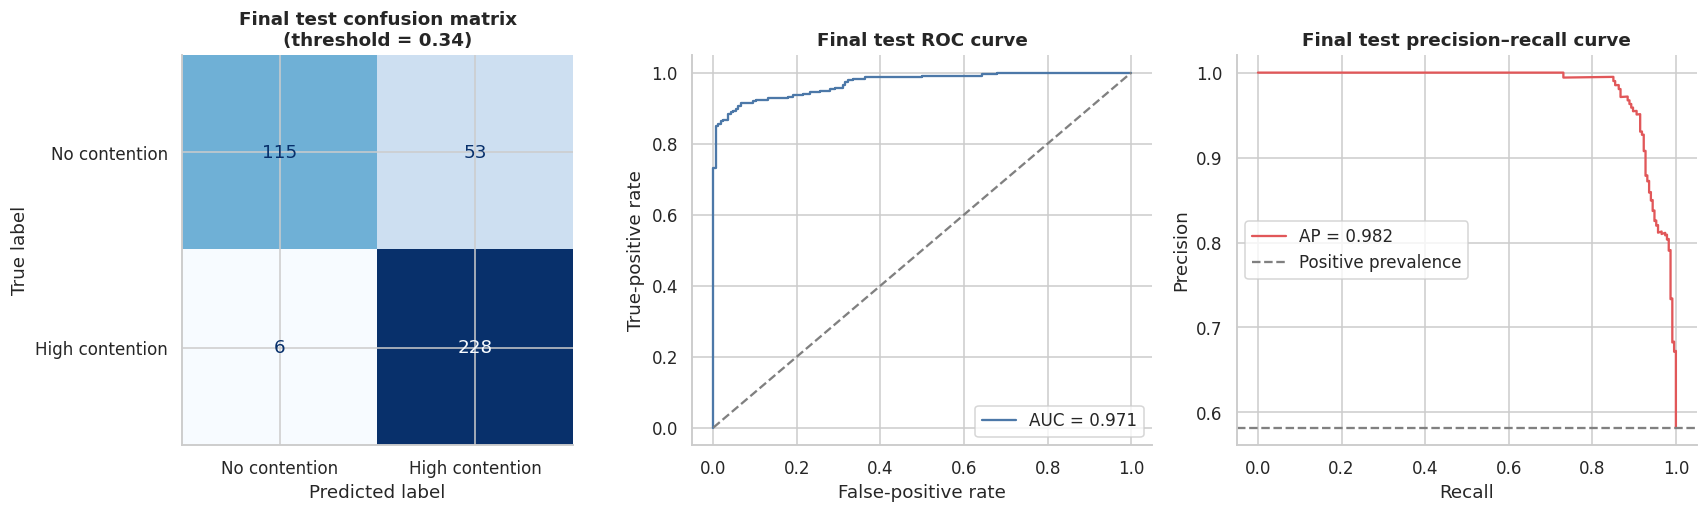

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ConfusionMatrixDisplay(test_matrix, display_labels=["No contention", "High contention"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title("Final test confusion matrix\n(threshold = 0.34)")

test_fpr, test_tpr, _ = roc_curve(y_test, test_probabilities)
axes[1].plot(test_fpr, test_tpr, color="#4C78A8", label=f"AUC = {computed_test_metrics['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("Final test ROC curve")
axes[1].set_xlabel("False-positive rate")
axes[1].set_ylabel("True-positive rate")
axes[1].legend()

test_precision_curve, test_recall_curve, _ = precision_recall_curve(y_test, test_probabilities)
axes[2].plot(test_recall_curve, test_precision_curve, color="#E15759",
             label=f"AP = {computed_test_metrics['pr_auc']:.3f}")
axes[2].axhline(y_test.mean(), linestyle="--", color="gray", label="Positive prevalence")
axes[2].set_title("Final test precision–recall curve")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
fig.tight_layout()
plt.show()

On 402 untouched rows from 9 held-out experiments, the final model obtains PR-AUC `0.9822`, ROC-AUC `0.9708`, recall `0.9744`, precision `0.8114`, and $F_2$ `0.9367`. It detects 228 of 234 positive rows, missing 6 and producing 53 false alarms. The test set was not used for model or threshold selection, and the model was not retrained during final evaluation.

## 11. Model interpretation

,Feature,Standardized coefficient,Absolute coefficient
14,hotspot_ratio,1.7107,1.7107
10,requests_per_sec,0.6429,0.6429
6,estimated_wait_age_ms,0.6062,0.6062
11,mean_latency_ms,0.5928,0.5928
0,active_transactions,0.5896,0.5896
3,total_locks,-0.5808,0.5808
8,configured_users,0.5758,0.5758
12,p95_latency_ms,0.4621,0.4621
1,blocked_sessions,0.4591,0.4591
5,connection_utilization,0.2408,0.2408


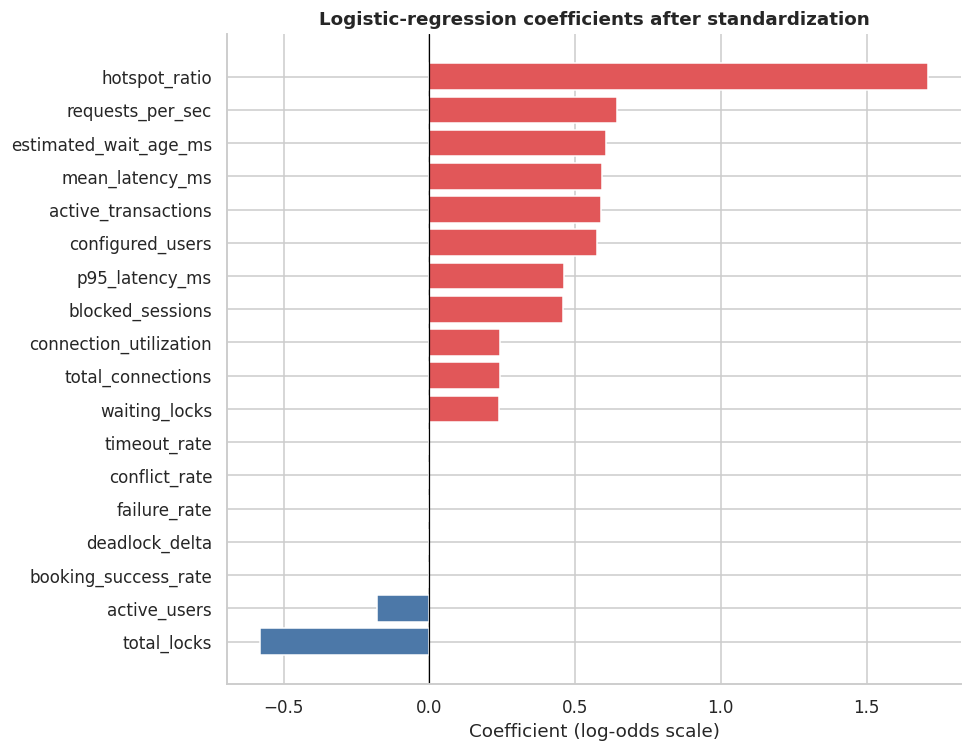

In [18]:
logistic_pipeline = artifact["model"]
coefficients = logistic_pipeline.named_steps["classifier"].coef_[0]
coefficient_table = pd.DataFrame(
    {"Feature": FEATURES, "Standardized coefficient": coefficients}
)
coefficient_table["Absolute coefficient"] = coefficient_table["Standardized coefficient"].abs()
coefficient_table = coefficient_table.sort_values("Absolute coefficient", ascending=False)
display(coefficient_table)

fig, ax = plt.subplots(figsize=(9, 7))
ordered = coefficient_table.sort_values("Standardized coefficient")
colors = np.where(ordered["Standardized coefficient"] >= 0, "#E15759", "#4C78A8")
ax.barh(ordered["Feature"], ordered["Standardized coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic-regression coefficients after standardization")
ax.set_xlabel("Coefficient (log-odds scale)")
plt.tight_layout()
plt.show()

,Feature,Mean PR-AUC decrease,Std. deviation
14,hotspot_ratio,0.1592,0.0095
3,total_locks,0.0223,0.0017
8,configured_users,0.0137,0.0029
6,estimated_wait_age_ms,0.0104,0.0056
11,mean_latency_ms,0.0091,0.0029
9,active_users,0.0077,0.0012
0,active_transactions,0.0064,0.0029
1,blocked_sessions,0.0057,0.0020
12,p95_latency_ms,0.0044,0.0021
10,requests_per_sec,0.0036,0.0032


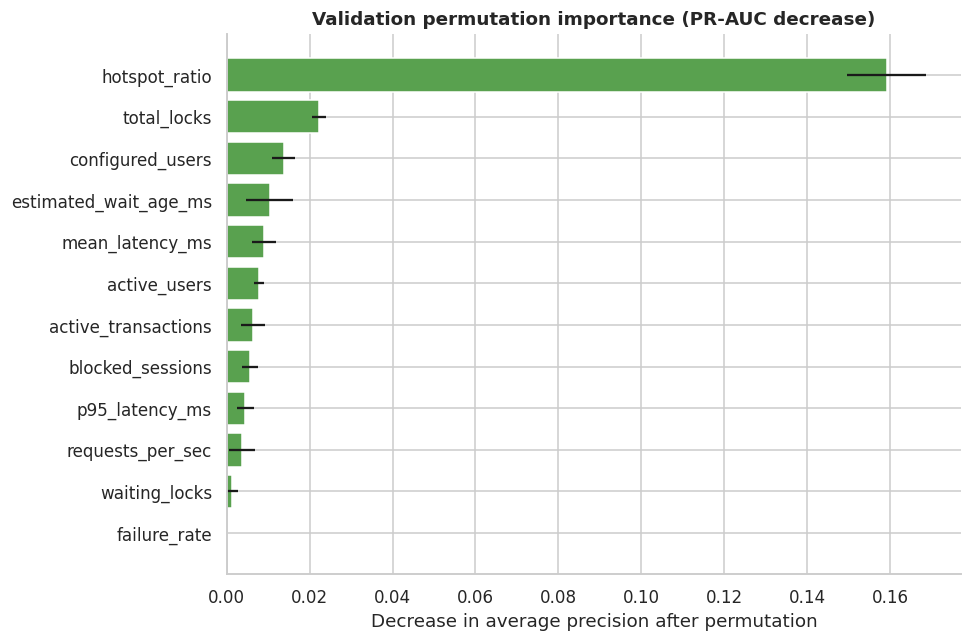

In [19]:
permutation = permutation_importance(
    logistic_pipeline,
    X_validation,
    y_validation,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_SEED,
    n_jobs=1,
)
permutation_table = pd.DataFrame(
    {
        "Feature": FEATURES,
        "Mean PR-AUC decrease": permutation.importances_mean,
        "Std. deviation": permutation.importances_std,
    }
).sort_values("Mean PR-AUC decrease", ascending=False)
display(permutation_table)

top = permutation_table.head(12).sort_values("Mean PR-AUC decrease")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["Feature"], top["Mean PR-AUC decrease"], xerr=top["Std. deviation"], color="#59A14F")
ax.set_title("Validation permutation importance (PR-AUC decrease)")
ax.set_xlabel("Decrease in average precision after permutation")
plt.tight_layout()
plt.show()

Coefficients describe changes in log odds for standardized features while holding other inputs fixed. Permutation importance estimates predictive reliance by measuring validation PR-AUC loss after shuffling one feature. Correlated telemetry can distribute importance across related variables, so neither view establishes causality. Together, they provide a transparent interpretation appropriate for the selected linear model without requiring a separate SHAP dependency.

## 12. Error analysis

,Rows,Median_probability,Median_blocked_sessions,Median_waiting_locks,Median_p95_latency_ms,Median_active_users
Outcome,,,,,,
True negative,115,0.0983,0.0,0.0,107.929,8.0
False positive,53,0.5085,0.0,0.0,710.184,18.0
False negative,6,0.2137,0.0,0.0,313.035,6.0
True positive,228,0.9774,2.0,2.0,786.148,9.0


,experiment_run_id,sampled_at,Probability,active_transactions,blocked_sessions,waiting_locks,total_locks,total_connections,connection_utilization,estimated_wait_age_ms,deadlock_delta,configured_users,active_users,requests_per_sec,mean_latency_ms,p95_latency_ms,failure_rate,hotspot_ratio,booking_success_rate,conflict_rate,timeout_rate
0,1506693d-8c92-4b6a-b7c6-23fafcdebbc0,2026-08-25 13:06:42.774846+05:30,0.0855,2,0,0,46,4,0.04,0.000,0,18,2,3.470,268.880,305.698,0.0,0.2857,1.0,0.0,0.0
1,1506693d-8c92-4b6a-b7c6-23fafcdebbc0,2026-08-25 13:06:44.770293+05:30,0.1088,5,0,0,115,7,0.07,0.000,0,18,5,9.021,270.009,294.723,0.0,0.2222,1.0,0.0,0.0
2,1506693d-8c92-4b6a-b7c6-23fafcdebbc0,2026-08-25 13:06:46.783880+05:30,0.1500,6,0,0,138,9,0.09,0.000,0,18,7,16.885,272.730,320.372,0.0,0.1765,1.0,0.0,0.0
13,1506693d-8c92-4b6a-b7c6-23fafcdebbc0,2026-08-25 13:07:08.770111+05:30,0.2774,10,0,0,230,12,0.12,0.000,0,18,18,24.004,475.926,545.870,0.0,0.1042,1.0,0.0,0.0
18,1506693d-8c92-4b6a-b7c6-23fafcdebbc0,2026-08-25 13:07:18.765281+05:30,0.3196,10,0,0,306,12,0.12,0.000,0,18,18,24.459,467.968,551.951,0.0,0.2449,1.0,0.0,0.0
330,dfeb53fd-ac77-47a0-970b-c7d9119e4616,2026-08-25 13:37:54.680644+05:30,0.3368,5,1,1,116,7,0.07,33.104,0,18,5,12.971,260.784,270.499,0.0,0.3846,1.0,0.0,0.0


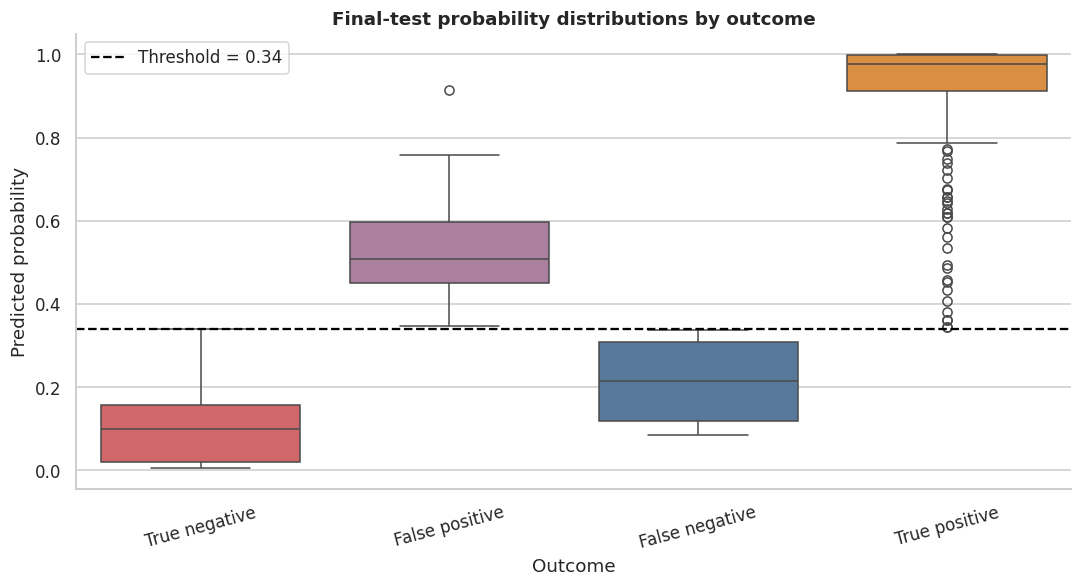

In [20]:
error_labels = np.select(
    [
        (y_test == 1) & (test_predictions == 1),
        (y_test == 0) & (test_predictions == 0),
        (y_test == 0) & (test_predictions == 1),
        (y_test == 1) & (test_predictions == 0),
    ],
    ["True positive", "True negative", "False positive", "False negative"],
    default="Unknown",
)
error_frame = splits["test"].loc[:, ["experiment_run_id", "sampled_at", *FEATURES, TARGET]].copy()
error_frame["Probability"] = test_probabilities
error_frame["Outcome"] = error_labels

error_summary = error_frame.groupby("Outcome").agg(
    Rows=(TARGET, "size"),
    Median_probability=("Probability", "median"),
    Median_blocked_sessions=("blocked_sessions", "median"),
    Median_waiting_locks=("waiting_locks", "median"),
    Median_p95_latency_ms=("p95_latency_ms", "median"),
    Median_active_users=("active_users", "median"),
).reindex(["True negative", "False positive", "False negative", "True positive"])
display(error_summary)

fig, ax = plt.subplots(figsize=(10, 5.5))
order = ["True negative", "False positive", "False negative", "True positive"]
sns.boxplot(data=error_frame, x="Outcome", y="Probability", order=order, ax=ax,
            palette=["#4C78A8", "#F28E2B", "#B279A2", "#E15759"], hue="Outcome", legend=False)
ax.axhline(selected_threshold, linestyle="--", color="black", label=f"Threshold = {selected_threshold:.2f}")
ax.set_title("Final-test probability distributions by outcome")
ax.set_ylabel("Predicted probability")
ax.tick_params(axis="x", rotation=15)
ax.legend()
plt.tight_layout()
plt.show()

display(
    error_frame.loc[error_frame["Outcome"] == "False negative",
                    ["experiment_run_id", "sampled_at", "Probability", *FEATURES]].sort_values("Probability")
)

False negatives are shown explicitly because missed contention is the higher-priority error. The selected threshold limits them to 6 of 234 positive test rows. False positives remain more frequent, which is the expected operational trade-off of optimizing $F_2$ for early warning. Whether that false-alarm rate is acceptable must ultimately be tested against the cost of interventions in a deployment setting.

## 13. Safe serialization check and deployment-compatible inference

In [21]:
selected_runtime_model = fitted_models["logistic_regression"]
reference_probabilities = selected_runtime_model.predict_proba(X_validation[:10])[:, 1]
with tempfile.TemporaryDirectory() as temporary_directory:
    temporary_model_path = Path(temporary_directory) / "serialization_check.joblib"
    joblib.dump(selected_runtime_model, temporary_model_path)
    reloaded_runtime_model = joblib.load(temporary_model_path)
    reloaded_probabilities = reloaded_runtime_model.predict_proba(X_validation[:10])[:, 1]
    temporary_size = temporary_model_path.stat().st_size

assert np.array_equal(reference_probabilities, reloaded_probabilities)
print(f"Temporary save/load round trip passed ({temporary_size:,} bytes).")
print("The tracked frozen artifact was not modified.")

Temporary save/load round trip passed (1,905 bytes).
The tracked frozen artifact was not modified.


In [22]:
from model_training.inference import ContentionPredictor

example_features = {
    feature: float(splits["test"].iloc[0][feature])
    for feature in FEATURES
}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    predictor = ContentionPredictor.load(artifact_path=ARTIFACT_PATH)
inference_result = predictor.predict(example_features)

example_output = pd.DataFrame(
    {
        "Field": [
            "Observed target", "Probability", "Risk level", "Threshold",
            "Model", "Target horizon (seconds)", "Artifact SHA-256",
        ],
        "Value": [
            int(splits["test"].iloc[0][TARGET]), inference_result.probability,
            inference_result.risk_level.value, inference_result.threshold_used,
            inference_result.model_name, inference_result.target_horizon_sec,
            inference_result.model_artifact_sha256,
        ],
    }
)
display(pd.Series(example_features, name="Example feature value").to_frame())
display(example_output)

,Example feature value
active_transactions,2.0000
blocked_sessions,0.0000
waiting_locks,0.0000
total_locks,46.0000
total_connections,4.0000
connection_utilization,0.0400
estimated_wait_age_ms,0.0000
deadlock_delta,0.0000
configured_users,18.0000
active_users,2.0000


,Field,Value
0,Observed target,1
1,Probability,0.0855
2,Risk level,LOW
3,Threshold,0.34
4,Model,contention-logistic-v1
5,Target horizon (seconds),30
6,Artifact SHA-256,e255db6ee5d3a59c075b6249fc7d355e5107dd56b2ed7d...


The inference example uses `ContentionPredictor`, the same validation and ordering layer used by the application. It requires exactly the 18 approved features, verifies the model artifact checksum, and returns probability, risk level, threshold, model provenance, feature schema, and the 30-second target horizon.

## 14. Relationship to the deployed system

In [23]:
live = phase7_report["live_experiment"]
phase7_table = pd.DataFrame(
    {
        "Deployment evidence": [
            "Experiment status", "Complete samples", "Predictions",
            "Coverage", "Missing predictions", "Duplicate predictions",
            "Stale predictions", "Matured labels", "Model versions used",
        ],
        "Result": [
            live["status"], live["complete_sample_count"], live["prediction_count"],
            live["coverage"], live["missing_prediction_count"],
            live["duplicate_prediction_count"], live["stale_prediction_count"],
            live["labeled_prediction_count"], live["model_version_count"],
        ],
    }
)
display(phase7_table)
assert live["passed"] is True
assert live["complete_sample_count"] == live["prediction_count"]

,Deployment evidence,Result
0,Experiment status,COMPLETED
1,Complete samples,15
2,Predictions,15
3,Coverage,1
4,Missing predictions,0
5,Duplicate predictions,0
6,Stale predictions,0
7,Matured labels,0
8,Model versions used,1


The application registers and activates the verified artifact, collects metric samples, creates one prediction per complete sample in an isolated transaction, and exposes authenticated prediction endpoints. The Phase 7 demonstration achieved 15/15 persistence coverage with one model version and no stale predictions.

This operational result must not be conflated with predictive accuracy: `labeled_prediction_count` is zero. Phase 7.5 should mature eligible live predictions using the same `(t, t+30s]` contract, then report live precision, recall, $F_2$, PR-AUC/ROC-AUC when both classes are present, calibration, workload-stratum performance, and drift relative to the frozen test evidence.

## 15. Final academic summary

- **Dataset:** 2,666 complete samples from 60 controlled PostgreSQL reservation experiments; 1,106 negative and 1,560 positive future-contention labels.
- **Prediction target:** whether high lock contention occurs in the following 30 seconds.
- **Preprocessing:** numeric validation and fixed feature ordering; standardization is fitted inside the logistic-regression pipeline. No imputation, categorical encoding, or outlier deletion is required.
- **Leakage control:** future-label evidence, target, identifiers, timestamps, completion state, and experimental controls are excluded. Entire experiments remain within one split.
- **Models evaluated:** prior-probability dummy, scaled logistic regression, and random forest.
- **Selection methodology:** validation PR-AUC selects the model; validation $F_2$ selects the decision threshold. The test set remains untouched until final evaluation.
- **Selected model:** StandardScaler + LogisticRegression at threshold `0.34`, chosen for the strongest validation PR-AUC and a transparent, lightweight deployment profile.
- **Final frozen test evidence:** PR-AUC `0.9822`, ROC-AUC `0.9708`, recall `0.9744`, precision `0.8114`, F1 `0.8854`, and $F_2$ `0.9367`; confusion matrix `TN=115`, `FP=53`, `FN=6`, `TP=228`.
- **Artifact reproducibility:** the frozen SHA-256-verified model exactly reproduces every stored test metric in this execution.
- **Deployment integration:** Phase 7 produced one persisted prediction for each of 15 complete live metric samples with 100% coverage.

### Limitations

1. The data comes from a controlled local PostgreSQL workload rather than a commercial production platform.
2. Experiment-grouped holdout evaluation tests unseen runs from the same designed campaign, not unseen infrastructure or organizations.
3. The project has a modest number of independent experimental groups (60), even though it contains 2,666 temporally related rows.
4. Feature correlation limits causal interpretation of coefficients and permutation importance.
5. The selected threshold emphasizes recall and consequently produces false positives.
6. Phase 7 live predictions have not yet received matured outcome labels; live generalization and calibration remain unverified.
7. Serialized sklearn models should be loaded with the locked scikit-learn `1.9.0` environment for authoritative reproduction.

### Recommended future work

Mature and score live predictions under the versioned label contract; repeat the campaign across more seeds, durations, infrastructure conditions, and contention regimes; monitor probability calibration and feature drift; and compare any future model against the same frozen grouped evaluation protocol before activation.